# Average and cumulative method ranks across metrics

For each metric and dataset, methods are ranked with **1 = best**. Ties receive their average rank. Dataset ranks are first averaged within each metric. The four metric ranks are then combined for every method:

- **Cumulative Rank**: sum of the four metric ranks.
- **Average Rank**: cumulative rank divided by 4.

`C3M_MC_NVI` is loaded from the ablation results and displayed as **LACE**. Synthetic datasets are excluded. All configured metrics are higher-is-better. The overall chart shows average rank next to a four-part cumulative bar, and four additional charts show the metric-specific average ranks. Each chart orders methods from best to worst, then appends the mean of all baseline methods (excluding LACE) after a dashed separator.

Using 22 common datasets and 17 common methods.

Per-metric rank summary (ordered within each metric):
       Metric     Method  Rank Order  Average Rank  Dataset Rank Sum  Datasets Ranked
     Accuracy       LACE           1      6.159091             135.5               22
     Accuracy       RDDM           2      6.545455             144.0               22
     Accuracy        LD3           3      7.295455             160.5               22
     Accuracy      ADWIN           4      7.681818             169.0               22
     Accuracy     MDDM_E           5      8.318182             183.0               22
     Accuracy FHDDMS_add           6      8.386364             184.5               22
     Accuracy     MDDM_G           7      8.454545             186.0               22
     Accuracy         ND           8      8.454545             186.0               22
     Accuracy     MDDM_A           9      8.613636             189.5               22
     Accuracy      FHDDM          10 

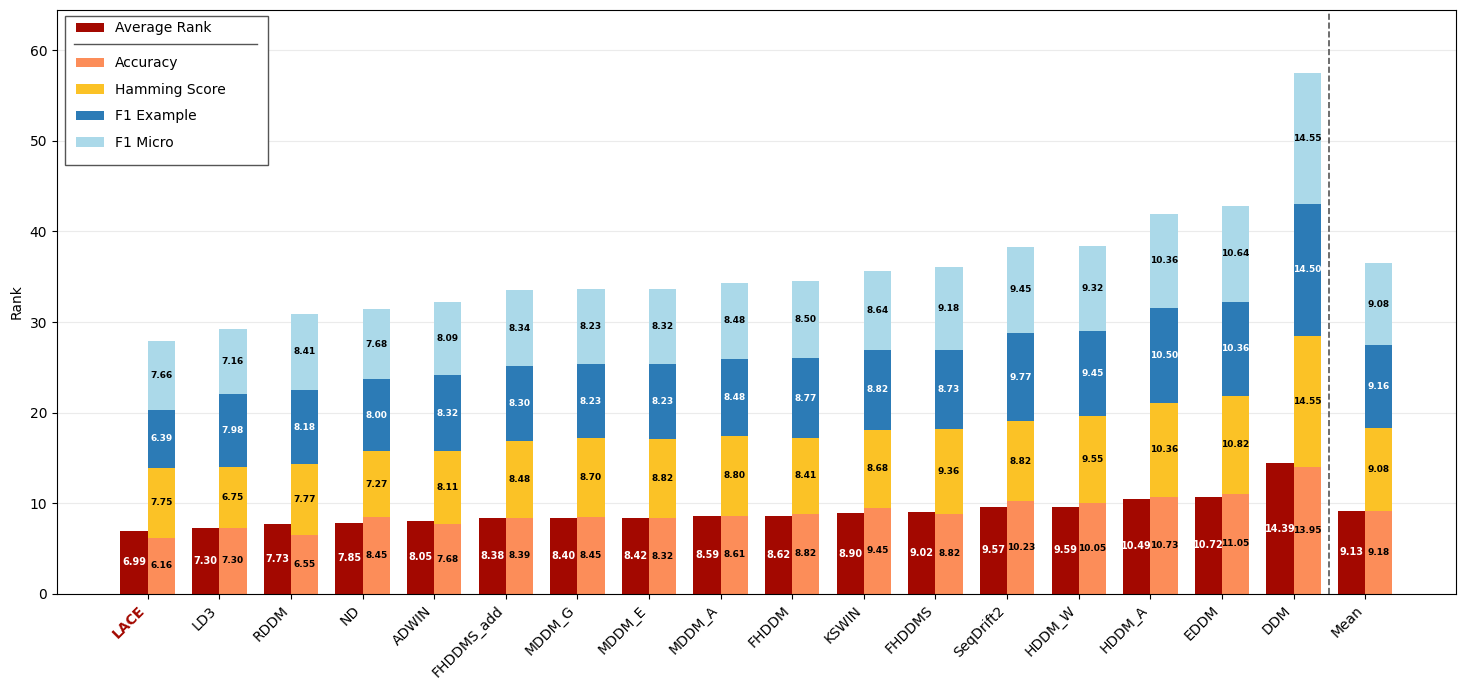

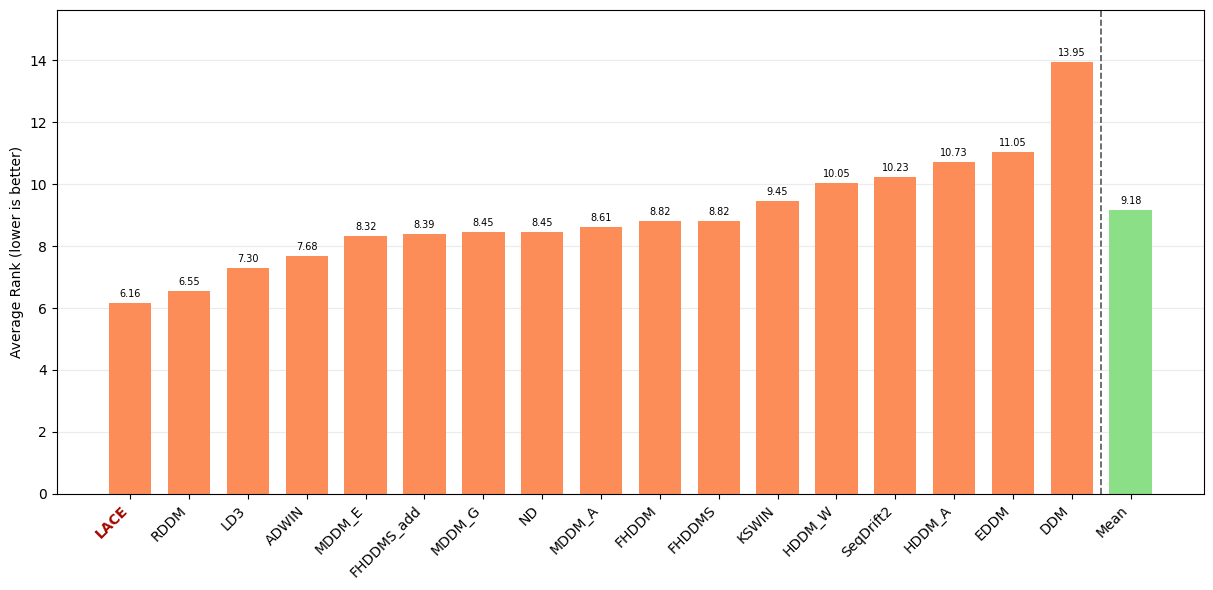

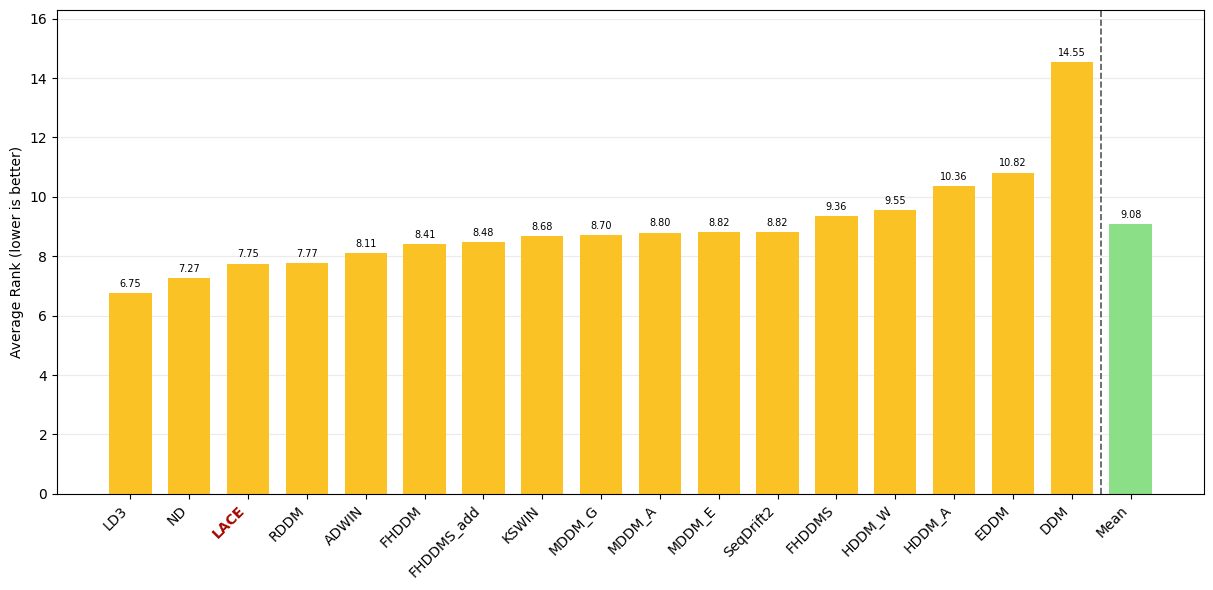

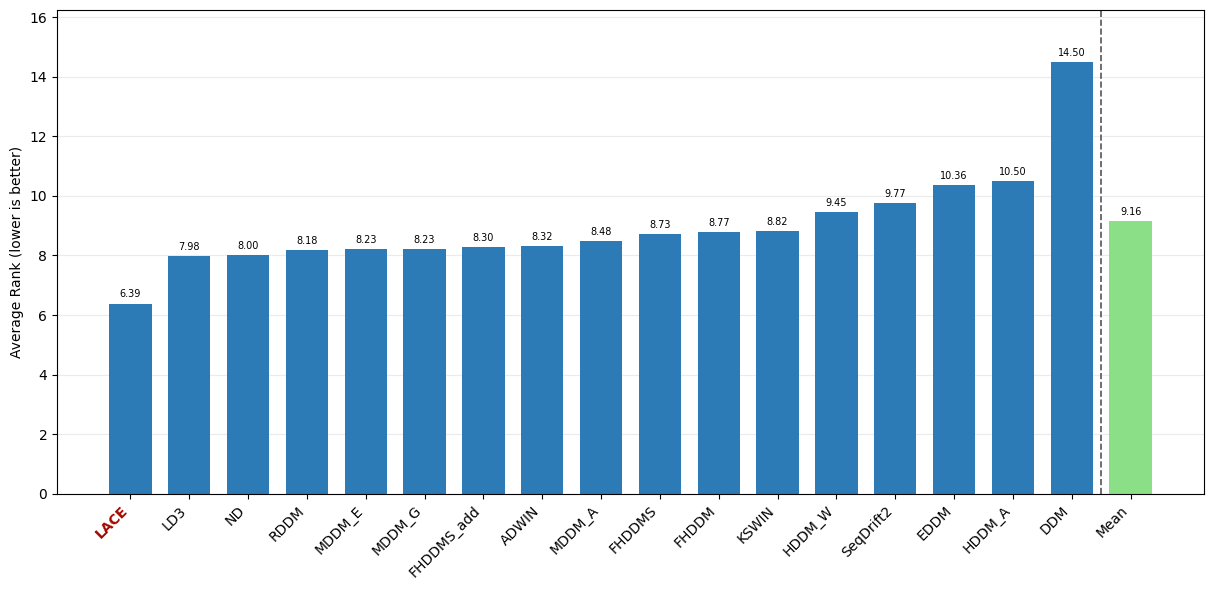

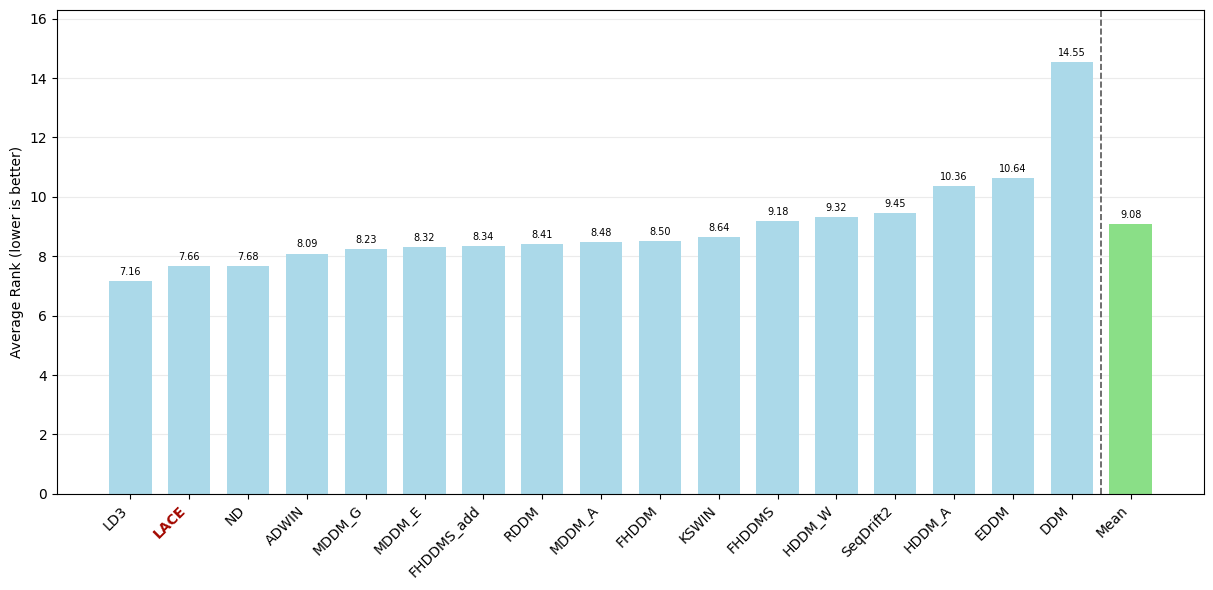

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# Configuration
# ============================================================

CSV_DIR = Path("outputs/csv/baseline")
ABLATION_CSV_DIR = Path("outputs/csv/ablation")
LACE_SOURCE_METHOD = "C3M_MC_NVI"
LACE_DISPLAY_NAME = "LACE"
SYNTHETIC_DATASET_PREFIX = "synthetic"

METRIC_FILES = {
    "Accuracy": "accuracy.csv",
    "Hamming Score": "hamming_score.csv",
    "F1 Example": "f1_example.csv",
    "F1 Micro": "f1_micro.csv",
}

# Change a value to False for a lower-is-better metric.
METRIC_HIGHER_IS_BETTER = {
    "Accuracy": True,
    "Hamming Score": True,
    "F1 Example": True,
    "F1 Micro": True,
}

METRIC_COLORS = {
    "Accuracy": "#fc8d59",
    "Hamming Score": "#fbc226",
    "F1 Example": "#2c7bb6",
    "F1 Micro": "#abd9e9",
}
MEAN_COLOR = "#8adf87"

# Known methods are kept in this order only while loading. Methods not listed
# here are still included; each final metric panel is ordered by rank.
PREFERRED_METHOD_ORDER = [
    "LACE",
    "LD3",
    "RDDM",
    "ND",
    "ADWIN",
    "DDM",
    "EDDM",
    "FHDDM",
    "FHDDMS",
    "FHDDMS_add",
    "HDDM_A",
    "HDDM_W",
    "KSWIN",
    "MDDM_A",
    "MDDM_E",
    "MDDM_G",
    "SeqDrift2",
]

SUMMARY_PATH = Path("rank_summary_by_metric.csv")
OVERALL_SUMMARY_PATH = Path("rank_summary_overall.csv")
DATASET_RANKS_PATH = Path("dataset_method_ranks.csv")
FIGURE_PATH = Path("average_cumulative_ranks_by_metric.png")
METRIC_FIGURE_PATHS = {
    metric: Path("{}_ranks.png".format(metric.lower().replace(" ", "_")))
    for metric in METRIC_FILES
}


# ============================================================
# Reading and validation
# ============================================================

def normalize_name(name):
    """Normalize names from plain or LaTeX-style CSV exports."""
    return (
        str(name)
        .strip()
        .replace("\\_", "_")
        .replace("{", "")
        .replace("}", "")
    )


def read_metric_csv(path):
    """Return a numeric dataset-by-method table regardless of CSV orientation."""
    if not path.exists():
        raise FileNotFoundError("Metric file not found: {}".format(path))

    table = pd.read_csv(path, index_col=0)
    table.index = [normalize_name(value) for value in table.index]
    table.columns = [normalize_name(value) for value in table.columns]

    index_is_methods = normalize_name(table.index.name).lower() == "method"
    known_methods = set(PREFERRED_METHOD_ORDER) | {LACE_SOURCE_METHOD}
    methods_in_index = sum(name in known_methods for name in table.index)
    methods_in_columns = sum(name in known_methods for name in table.columns)
    if index_is_methods or methods_in_index > methods_in_columns:
        table = table.T

    if table.index.has_duplicates or table.columns.has_duplicates:
        raise ValueError("Duplicate dataset or method names in {}".format(path))

    return table.apply(pd.to_numeric, errors="coerce")


def load_metric_tables():
    """Merge baseline methods with ablation C3M_MC_NVI, displayed as LACE."""
    metric_tables = {}

    for metric, filename in METRIC_FILES.items():
        baseline = read_metric_csv(CSV_DIR / filename)
        ablation = read_metric_csv(ABLATION_CSV_DIR / filename)

        if LACE_SOURCE_METHOD not in ablation.columns:
            raise ValueError(
                "{} is missing from {}".format(
                    LACE_SOURCE_METHOD, ABLATION_CSV_DIR / filename
                )
            )

        real_datasets = [
            dataset
            for dataset in baseline.index
            if not dataset.lower().startswith(SYNTHETIC_DATASET_PREFIX)
        ]
        missing_lace_datasets = sorted(set(real_datasets).difference(ablation.index))
        if missing_lace_datasets:
            raise ValueError(
                "LACE results are missing for datasets: {}".format(
                    missing_lace_datasets
                )
            )

        combined = baseline.loc[real_datasets].copy()
        combined[LACE_DISPLAY_NAME] = ablation.loc[
            real_datasets, LACE_SOURCE_METHOD
        ]
        metric_tables[metric] = combined

    return metric_tables


def common_items(metric_tables):
    """Find datasets and methods available in every configured metric."""
    dataset_sets = [set(table.index) for table in metric_tables.values()]
    method_sets = [set(table.columns) for table in metric_tables.values()]

    datasets = sorted(set.intersection(*dataset_sets))
    methods = set.intersection(*method_sets)

    preferred = [method for method in PREFERRED_METHOD_ORDER if method in methods]
    extra = sorted(methods.difference(preferred))
    ordered_methods = preferred + extra

    if not datasets:
        raise ValueError("No datasets are shared by all metric files.")
    if not ordered_methods:
        raise ValueError("No methods are shared by all metric files.")

    return datasets, ordered_methods


# ============================================================
# Ranking
# ============================================================

def compute_rank_summaries(metric_tables):
    """Compute dataset-level, per-metric, and overall method ranks."""
    common_datasets, common_methods = common_items(metric_tables)
    per_metric_parts = []
    dataset_rank_parts = []

    for metric, table in metric_tables.items():
        selected = table.loc[common_datasets, common_methods]
        if selected.isna().any().any():
            missing = selected.isna().stack()
            missing = missing[missing].index.tolist()
            raise ValueError(
                "Missing/non-numeric values for {}: {}".format(metric, missing[:10])
            )

        ranks = selected.rank(
            axis=1,
            ascending=not METRIC_HIGHER_IS_BETTER[metric],
            method="average",
        )

        metric_summary = pd.DataFrame({
            "Metric": metric,
            "Method": common_methods,
            "Average Rank": ranks.mean(axis=0).reindex(common_methods).to_numpy(),
            "Dataset Rank Sum": ranks.sum(axis=0).reindex(common_methods).to_numpy(),
            "Datasets Ranked": ranks.count(axis=0).reindex(common_methods).to_numpy(),
        })
        metric_summary = metric_summary.sort_values(
            ["Average Rank", "Dataset Rank Sum", "Method"],
            kind="stable",
        ).reset_index(drop=True)
        metric_summary.insert(2, "Rank Order", np.arange(1, len(metric_summary) + 1))
        per_metric_parts.append(metric_summary)

        rank_long = (
            ranks.rename_axis(index="Dataset", columns="Method")
            .stack()
            .rename("Rank")
            .reset_index()
        )
        rank_long.insert(0, "Metric", metric)
        dataset_rank_parts.append(rank_long)

    per_metric_summary = pd.concat(per_metric_parts, ignore_index=True)
    dataset_ranks = pd.concat(dataset_rank_parts, ignore_index=True)

    metric_names = list(METRIC_FILES)
    metric_rank_wide = (
        per_metric_summary.pivot(
            index="Method", columns="Metric", values="Average Rank"
        )
        .reindex(columns=metric_names)
    )
    if metric_rank_wide.isna().any().any():
        raise ValueError("Every method must have a rank for all configured metrics.")

    metric_rank_wide["Cumulative Rank"] = metric_rank_wide[metric_names].sum(axis=1)
    metric_rank_wide["Average Rank"] = (
        metric_rank_wide["Cumulative Rank"] / len(metric_names)
    )
    overall_summary = (
        metric_rank_wide.reset_index()
        [["Method"] + metric_names + ["Average Rank", "Cumulative Rank"]]
        .sort_values(["Average Rank", "Cumulative Rank", "Method"], kind="stable")
        .reset_index(drop=True)
    )
    overall_summary.insert(1, "Rank Order", np.arange(1, len(overall_summary) + 1))

    return (
        per_metric_summary,
        overall_summary,
        dataset_ranks,
        common_datasets,
        common_methods,
    )


# ============================================================
# Plotting
# ============================================================

def append_baseline_mean(rank_data, value_columns):
    """Append a display-only mean computed from every method except LACE."""
    baseline_rows = rank_data[rank_data["Method"] != LACE_DISPLAY_NAME]
    if baseline_rows.empty:
        raise ValueError("No baseline methods are available for the mean.")

    mean_row = {"Method": "Mean"}
    mean_row.update(baseline_rows[value_columns].mean().to_dict())
    return pd.concat([rank_data, pd.DataFrame([mean_row])], ignore_index=True)


def add_mean_separator(axis, number_of_rows):
    """Draw a divider immediately before the final Mean category."""
    axis.axvline(
        number_of_rows - 1.5, color="#555555", linewidth=1.2, linestyle="--"
    )


def plot_average_and_cumulative_ranks(overall_summary, output_path):
    """Plot average rank beside a four-metric stacked cumulative rank."""
    rank_data = overall_summary.sort_values("Rank Order").reset_index(drop=True)
    value_columns = list(METRIC_FILES) + ["Average Rank", "Cumulative Rank"]
    rank_data = append_baseline_mean(rank_data, value_columns)
    x = np.arange(len(rank_data))
    width = 0.38
    figure_width = max(14, len(rank_data) * 0.82)
    fig, axis = plt.subplots(figsize=(figure_width, 7))

    color_palette = ["#a30800", "#fc8d59", "#fbc226", "#2c7bb6", "#abd9e9"]

    average_bars = axis.bar(
        x - width / 2,
        rank_data["Average Rank"],
        width,
        color=color_palette[0],
        label="Average Rank (cumulative / 4)",
    )

    metric_text_colors = {
        "Accuracy": "black",
        "Hamming Score": "black",
        "F1 Example": "white",
        "F1 Micro": "black",
    }
    cumulative_bottom = np.zeros(len(rank_data))
    cumulative_legend_handles = []
    for metric in METRIC_FILES:
        metric_values = rank_data[metric].to_numpy()
        metric_bars = axis.bar(
            x + width / 2,
            metric_values,
            width,
            bottom=cumulative_bottom,
            color=METRIC_COLORS[metric],
            label=metric,
        )
        cumulative_legend_handles.append(metric_bars)
        axis.bar_label(
            metric_bars,
            fmt="%.2f",
            label_type="center",
            fontsize=6.5,
            fontweight="bold",
            color=metric_text_colors[metric],
            rotation=0,
        )
        cumulative_bottom += metric_values

    axis.set_xticks(x)
    tick_labels = axis.set_xticklabels(
        rank_data["Method"], rotation=45, ha="right"
    )
    for tick_label in tick_labels:
        if tick_label.get_text() == LACE_DISPLAY_NAME:
            tick_label.set_color("#a30800")
            tick_label.set_fontweight("bold")
    axis.set_ylabel("Rank")
    add_mean_separator(axis, len(rank_data))
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
    legend_background = plt.Rectangle(
        (0.006, 0.735),
        0.145,
        0.255,
        transform=axis.transAxes,
        facecolor="white",
        edgecolor="#555555",
        linewidth=1.0,
        zorder=3,
    )
    axis.add_patch(legend_background)
    average_legend = axis.legend(
        [average_bars],
        ["Average Rank"],
        loc="upper left",
        bbox_to_anchor=(0.01, 0.99),
        borderaxespad=0,
        frameon=False,
        ncol=1,
    )
    axis.add_artist(average_legend)
    axis.plot(
        [0.012, 0.143],
        [0.942, 0.942],
        transform=axis.transAxes,
        color="#555555",
        linewidth=1.0,
        zorder=4,
        clip_on=False,
    )
    axis.legend(
        cumulative_legend_handles,
        list(METRIC_FILES),
        loc="upper left",
        bbox_to_anchor=(0.01, 0.930),
        borderaxespad=0,
        frameon=False,
        ncol=1,
        labelspacing=0.9,
    )
    axis.bar_label(
        average_bars,
        fmt="%.2f",
        label_type="center",
        fontsize=7,
        fontweight="bold",
        color="white",
        rotation=0,
    )
    axis.margins(y=0.12)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_metric_ranks(per_metric_summary, output_paths):
    """Create one average-rank bar chart for each configured metric."""
    for metric in METRIC_FILES:
        rank_data = (
            per_metric_summary[per_metric_summary["Metric"] == metric]
            .sort_values("Rank Order")
            .reset_index(drop=True)
        )
        rank_data = append_baseline_mean(rank_data, ["Average Rank"])
        x = np.arange(len(rank_data))
        colors = [METRIC_COLORS[metric]] * len(rank_data)
        colors[-1] = MEAN_COLOR

        fig, axis = plt.subplots(figsize=(max(12, len(rank_data) * 0.68), 6))
        bars = axis.bar(x, rank_data["Average Rank"], color=colors, width=0.72)
        axis.bar_label(bars, fmt="%.2f", padding=3, fontsize=7)
        axis.set_xticks(x)
        tick_labels = axis.set_xticklabels(
            rank_data["Method"], rotation=45, ha="right"
        )
        for tick_label in tick_labels:
            if tick_label.get_text() == LACE_DISPLAY_NAME:
                tick_label.set_color("#a30800")
                tick_label.set_fontweight("bold")
        axis.set_ylabel("Average Rank (lower is better)")
        axis.grid(axis="y", alpha=0.25)
        axis.set_axisbelow(True)
        add_mean_separator(axis, len(rank_data))
        axis.margins(y=0.12)
        fig.tight_layout()
        fig.savefig(output_paths[metric], dpi=300, bbox_inches="tight")
        plt.show()


# ============================================================
# Run analysis
# ============================================================

metric_tables = load_metric_tables()

(
    rank_summary_by_metric,
    rank_summary_overall,
    dataset_method_ranks,
    common_datasets,
    common_methods,
) = compute_rank_summaries(metric_tables)

rank_summary_by_metric.to_csv(SUMMARY_PATH, index=False)
rank_summary_overall.to_csv(OVERALL_SUMMARY_PATH, index=False)
dataset_method_ranks.to_csv(DATASET_RANKS_PATH, index=False)

print("Using {} common datasets and {} common methods.".format(
    len(common_datasets), len(common_methods)
))
print("\nPer-metric rank summary (ordered within each metric):")
print(rank_summary_by_metric.to_string(index=False))
print("\nOverall rank summary:")
print(rank_summary_overall.to_string(index=False))

plot_average_and_cumulative_ranks(rank_summary_overall, FIGURE_PATH)
plot_metric_ranks(rank_summary_by_metric, METRIC_FIGURE_PATHS)
